# 💧 LFM2.5-VL - Vision Capabilities

This notebook runs the examples from the [Vision Capabilities](https://docs.liquid.ai/lfm/key-concepts/vision-capabilities), [Tool Calling](https://docs.liquid.ai/lfm/key-concepts/tool-use) documentation with [`LiquidAI/LFM2.5-VL-3B`](https://huggingface.co/LiquidAI/LFM2.5-VL-3B). The code matches the documentation, so you can run each example end to end.

## Setup

Install PyTorch, Transformers, and the image packages used by the examples. `torchvision` and `Pillow` are required by the image processor, and `opencv-python` draws the layout boxes.

The examples use the recommended sampling parameters for the model shown. For another model, use the values from its model page.

In [ ]:
%pip install -q torch torchvision accelerate pillow opencv-python "transformers>=5.10.1"

Load the model with `AutoProcessor` and `AutoModelForImageTextToText`:

In [ ]:
import torch
from transformers import AutoProcessor, AutoModelForImageTextToText

MODEL_ID = "LiquidAI/LFM2.5-VL-3B"

processor = AutoProcessor.from_pretrained(MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID,
    device_map="auto",
    dtype="bfloat16",
)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


processor_config.json:   0%|          | 0.00/828 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/5.44k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/5.09k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/507 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.9MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 6.25GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/707 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/327 [00:00<?, ?B/s]

## Single-image prompt

Provide one image and a text question in the same user message. This pattern is useful for captioning, visual question answering, and scene understanding.
![Input image](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/coco_sample.png)

In [ ]:
from transformers.image_utils import load_image

img_url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/coco_sample.png"
input_image = load_image(img_url)

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": input_image},
            {"type": "text", "text": "Describe this image in two concise sentences."},
        ],
    }
]

In [ ]:
# Apply chat template
inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device)

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        do_sample=True,
        temperature=0.2,
        top_k=50,
        repetition_penalty=1.0,
        max_new_tokens=256,
    )

answer = processor.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
print(answer)

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.


Two cats are sleeping on a pink couch next to two remote controls.


## Multi-image prompt

You can include multiple images in a single prompt. Label each image in the prompt, such as `Media-1` and `Media-2`, to make cross-image references clearer.
![Media-1 input](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/p-blog/candy.JPG)
![Media-2 input](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/coco_sample.png)


In [ ]:
img_urls = [
    "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/p-blog/candy.JPG",
    "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/coco_sample.png",
]
input_images = [load_image(img_url) for img_url in img_urls]

messages = [
    {
        "role": "user",
        "content": [
            {"type": "text", "text": "Media-1\n"},
            {"type": "image", "image": input_images[0]},
            {"type": "text", "text": "\nMedia-2\n"},
            {"type": "image", "image": input_images[1]},
            {"type": "text", "text": "\nCaption Media-1 and Media-2 separately. Keep each caption to one sentence."},
        ],
    }
]

In [ ]:
# Apply chat template
inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device)

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        do_sample=True,
        temperature=0.2,
        top_k=50,
        repetition_penalty=1.0,
        max_new_tokens=256,
    )

answer = processor.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
print(answer)

Media-1: A person holds a handful of colorful M&Ms featuring bee and leaf designs in their palm.

Media-2: Two cats are peacefully sleeping on a pink couch, each with a remote control nearby.


## OCR

LFM vision models read text in document images and screenshots. OCR works best when text is legible and the image is not blurry, rotated, or heavily compressed. For dense documents, crop to the relevant page or region when possible.
![Input image](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/enterprise/audit-logs.png)

In [ ]:
img_url = "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/enterprise/audit-logs.png"
document_image = load_image(img_url)

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": document_image},
            {
                "type": "text",
                "text": "Read this audit log screenshot. Identify the page heading, table columns, visible rows, users, actions, timestamps, and other structured fields. Transcribe the visible text in reading order.",
            },
        ],
    }
]

In [ ]:
# Apply chat template
inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device)

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        do_sample=True,
        temperature=0.2,
        top_k=50,
        repetition_penalty=1.0,
        max_new_tokens=512,
    )

answer = processor.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
print(answer)

Audit log

| Events log | Download as JSON |
| --- | --- |
| clboetticher org.update_join_settings | |
| clboetticher enabled join requests with manual approval and set default role to write | United States, Austin · 136.62.181.0 · On Oct 15 |
| clboetticher repo.delete | |
| clboetticher deleted a model: enterprise-explorers/test_model | United States, Austin · 136.62.181.0 · On Oct 10 |
| clboetticher repo.create | |
| clboetticher created a public model: enterprise-explorers/test_model | United States, Austin · 136.62.181.0 · On Oct 10 |
| System billing.renew_subscription | |
| System Automatic subscription renewal for hf/enterprise-free | Unknown Location · On Oct 7 |
| derek-thomas resource_group.add_users | |
| derek-thomas added users to resource group Read access members: derek-thomas (read) | United Arab Emirates, Abu Dhabi · 217.164.173.0 · On Sep 17 |
| erikrigner resource_group.change_role | |
| erikrigner changed role for user erikrigner in resource group Read access memb

## Document layout annotations

For document understanding tasks, a compatible vision model can return OCR with layout annotations. Each region contains a label, normalized bounding box, and content:

Coordinates are normalized integers in `[0, 1000]`, matching the [grounding](https://docs.liquid.ai/lfm/key-concepts/vision-capabilities#object-detection-and-grounding) format. To visualize the boxes, scale the coordinates back to pixels with `x / 1000 * width` and `y / 1000 * height`.

image_index=0 label [76, 68, 144, 94]
Acme Inc.

image_index=0 text [78, 102, 104, 121]
acme

image_index=0 text [28, 176, 66, 197]
Profile

image_index=0 text [28, 230, 74, 252]
Account

image_index=0 text [28, 282, 80, 304]
Members

image_index=0 text [28, 334, 64, 357]
Billing

image_index=0 text [28, 387, 118, 406]
Access Tokens

image_index=0 text [122, 388, 174, 406]
Enterprise

image_index=0 text [28, 438, 72, 462]
Regions

image_index=0 text [89, 438, 141, 461]
Enterprise

image_index=0 text [28, 490, 52, 512]
SSO

image_index=0 text [68, 490, 120, 512]
Enterprise

image_index=0 text [28, 545, 84, 569]
Audit Log

image_index=0 text [96, 545, 151, 567]
Enterprise

image_index=0 text [28, 599, 120, 618]
Resource Groups

image_index=0 text [136, 599, 188, 618]
Enterprise

image_index=0 text [28, 650, 128, 670]
Advanced Security

image_index=0 text [144, 650, 197, 670]
Enterprise

image_index=0 text [28, 701, 87, 722]
Analytics

image_index=0 text [96, 701, 149, 722]
Enterprise

im

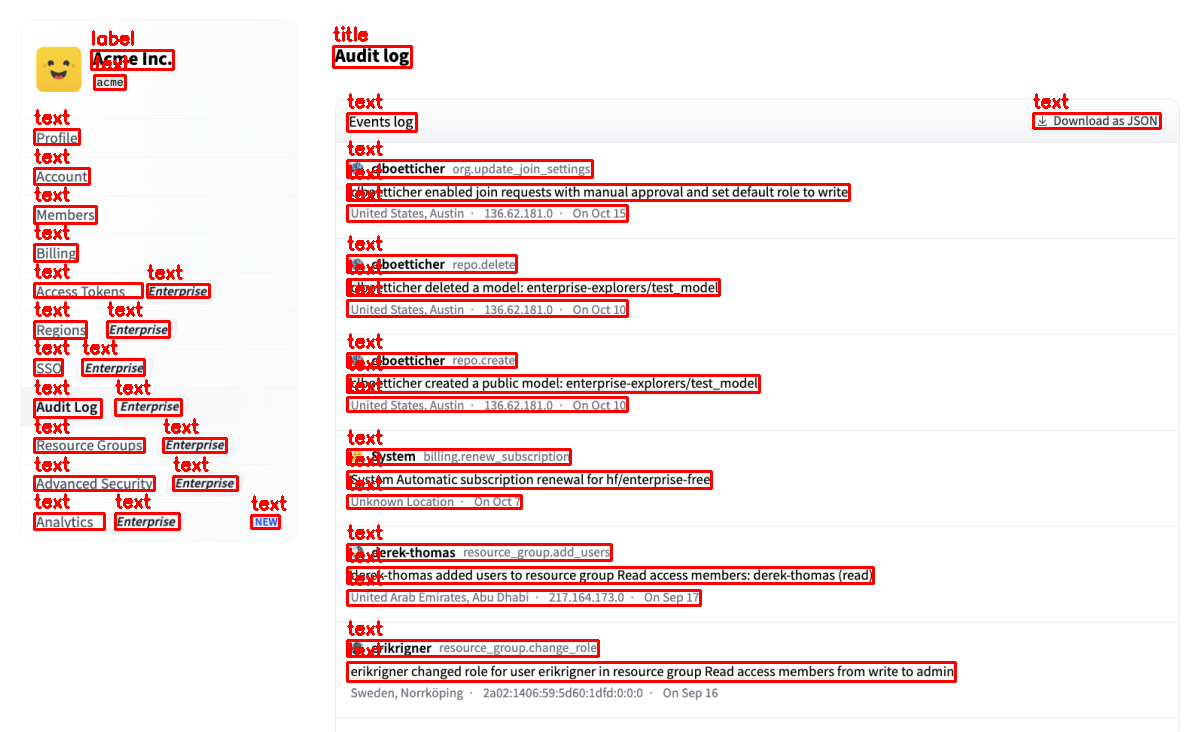

In [ ]:
import re
import cv2
import numpy as np
from IPython.display import display
from PIL import Image

layout_prompt = """Parse this document into its layout regions. The pages are provided as images in reading order. For every region, in reading order across all pages, output a header line immediately followed by the region's content:

image_index=<n> <label> [xmin, ymin, xmax, ymax]
<content>

where:
- image_index is the zero-based index of the page image the region appears on (0 for the first image, 1 for the second, and so on)
- <label> is one of these layout labels: text, title, list, table, table_caption, table_footnote, image, image_block, image_caption, image_footnote, chart, equation, formula_number, code, code_caption, algorithm, aside_text, ref_text, phonetic, page_header, page_footer, page_number, page_footnote
- [xmin, ymin, xmax, ymax] are normalized integer coordinates in [0, 1000]
- <content> is the region's content: plain text for text regions, LaTeX for equations, OTSL for tables, and a short description for images and charts

Separate each region block with one blank line. Return only the parsed regions.
"""

messages = [
    {
        "role": "user",
        "content": [
            {"type": "image", "image": document_image},
            {"type": "text", "text": layout_prompt},
        ],
    }
]

# Apply chat template
inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device)

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        do_sample=True,
        temperature=0.2,
        top_k=50,
        repetition_penalty=1.0,
        max_new_tokens=1024,
    )

answer = processor.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
print(answer)

pattern = re.compile(r"image_index=0\s+([a-z_]+)\s+\[(\d+),\s*(\d+),\s*(\d+),\s*(\d+)\]")

image = np.array(document_image).copy()
height, width = image.shape[:2]

for label, xmin, ymin, xmax, ymax in pattern.findall(answer):
    xmin, ymin, xmax, ymax = map(int, [xmin, ymin, xmax, ymax])
    pt1 = (round(xmin / 1000 * width), round(ymin / 1000 * height))
    pt2 = (round(xmax / 1000 * width), round(ymax / 1000 * height))
    cv2.rectangle(image, pt1, pt2, (255, 0, 0), 2)
    cv2.putText(image, label, (pt1[0], max(20, pt1[1] - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

display(Image.fromarray(image))

![Layout regions drawn on the audit log screenshot](https://docs.liquid.ai/images/lfm/key-concepts/vision-capabilities/cell-13-output-5.png)

## Object detection and grounding

Grounding asks the model to localize visible objects with bounding boxes. This example uses the cat photo from [Single-image prompt](https://docs.liquid.ai/lfm/key-concepts/vision-capabilities#single-image-prompt), asks for boxes in `[xmin, ymin, xmax, ymax]` format normalized to `[0, 1000]`, then draws the returned boxes.

Convert normalized coordinates back to pixels with `x / 1000 * width` and `y / 1000 * height`. Boxes are approximate, so visually inspect the result before using coordinates in downstream workflows.

In [ ]:
import json
import re
from IPython.display import display
from PIL import ImageDraw

system_prompt = """When asked for bounding boxes for objects, return a valid JSON array.
Each array item must be an object with:
- bbox_2d: [xmin, ymin, xmax, ymax] normalized integer coordinates in [0, 1000]
- label: a concise label you choose for the predicted object or region

Return one item per visible matching object or region. Return [] if none are visible."""

messages = [
    {"role": "system", "content": system_prompt},
    {
        "role": "user",
        "content": [
            {"type": "image", "image": input_image},
            {"type": "text", "text": "Provide bounding boxes for the two cats and the two remote controls."},
        ],
    },
]

In [ ]:
# Apply chat template
inputs = processor.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device)

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        do_sample=True,
        temperature=0.2,
        top_k=50,
        repetition_penalty=1.0,
        max_new_tokens=256,
    )

answer = processor.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)
print(answer)

[{"image_id": 0, "bbox_2d": [543, 49, 1000, 774], "label": "cat on the right"}, {"image_id": 0, "bbox_2d": [10, 112, 496, 986], "label": "cat on the left"}, {"image_id": 0, "bbox_2d": [523, 158, 581, 399], "label": "remote on the right"}, {"image_id": 0, "bbox_2d": [63, 151, 276, 244], "label": "remote on the left"}]


Then draw the boxes:

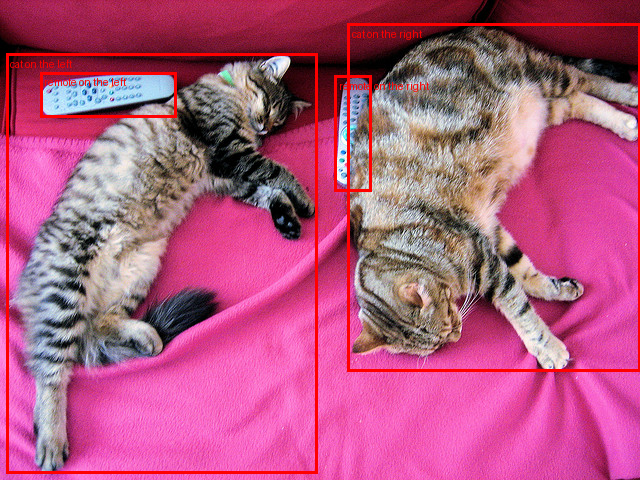

In [ ]:
objects = json.loads(re.search(r"\[.*\]", answer, flags=re.DOTALL).group(0))
annotated = input_image.copy()
draw = ImageDraw.Draw(annotated)
width, height = annotated.size
for obj in objects:
    xmin, ymin, xmax, ymax = obj["bbox_2d"]
    box = (xmin / 1000 * width, ymin / 1000 * height, xmax / 1000 * width, ymax / 1000 * height)
    draw.rectangle(box, outline="red", width=3)
    draw.text((box[0] + 4, box[1] + 4), obj.get("label", ""), fill="red")
display(annotated)

![Bounding boxes drawn around the cats and remote controls](https://docs.liquid.ai/images/lfm/key-concepts/vision-capabilities/cell-15-output-6.png)

## Tool calling

Vision models can use what they see to choose a tool and fill in its arguments. In this example, the model sees a photo of two cats and routes a request to the most relevant of two tools.

This example shows how to define the tools and generate the tool call. Executing the call and generating the final answer work the same as in [Text Models](https://docs.liquid.ai/lfm/key-concepts/tool-use#text-models).

Load the vision model as shown in [Vision Capabilities](https://docs.liquid.ai/lfm/key-concepts/vision-capabilities#setup). This example uses the same image and request for both model families:
![Input image](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/coco_sample.png)

In [ ]:
from transformers.image_utils import load_image

input_image = load_image("https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/coco_sample.png")
messages = [{
    "role": "user",
    "content": [
        {"type": "image", "image": input_image},
        {"type": "text", "text": "Find a care guide for the animals in this image. Choose the best tool for this request."},
    ],
}]

Pass the tool schemas with `tools=...`:

In [ ]:
tools = [
    {
        "name": "search_pet_care",
        "description": "Search for care guidance for an animal visible in an image.",
        "parameters": {
            "type": "object",
            "properties": {
                "animal": {"type": "string", "description": "The animal visible in the image"},
                "topic": {"type": "string", "description": "The care topic to search for"},
            },
            "required": ["animal", "topic"],
        },
    },
    {
        "name": "search_replacement_remote",
        "description": "Search for replacement remote controls or remote-control accessories visible in an image.",
        "parameters": {
            "type": "object",
            "properties": {
                "item": {"type": "string", "description": "The remote-control item to search for"},
                "quantity": {"type": "integer", "description": "How many matching items are visible"},
            },
            "required": ["item"],
        },
    },
]

# Apply chat template
inputs = processor.apply_chat_template(
    messages,
    tools=tools,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(model.device)

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        do_sample=True,
        temperature=0.2,
        top_k=50,
        repetition_penalty=1.0,
        max_new_tokens=256,
    )

text = processor.decode(outputs[0, inputs["input_ids"].shape[1]:], skip_special_tokens=False)
answer = text.replace("<|im_end|>", "").strip()
print(answer)

<|tool_call_start|>[search_pet_care(animal='cat', topic='sleep')]<|tool_call_end|>


## FAQ

### Which LFM2.5-VL model should I use?

Use `LFM2.5-VL-450M` or `LFM2.5-VL-1.6B` for fast image captioning and visual question answering. Use `LFM2.5-VL-3B` for the strongest support for multi-image prompts, grounding, document layout parsing, and tool calling.

### What image formats are supported?

LFM2.5-VL works with common image formats supported by the image loading path you use, such as JPEG and PNG. In the examples above, images are loaded from Hugging Face URLs with `transformers.image_utils.load_image`.

### Can LFM2.5-VL return bounding boxes?

Yes. For grounding tasks, prompt the model to return bounding boxes in a structured format such as JSON. Coordinates in these examples are normalized to `[0, 1000]`, so you can scale them back to the displayed image size.

Note that bounding boxes are approximate and can vary with prompt wording, image resolution, and generation settings. For workflows that require precise localization, inspect the returned boxes and validate them against the original image.

### Can LFM2.5-VL parse documents?

Yes. `LFM2.5-VL-3B` can read visible text and return document layout annotations, including region labels, bounding boxes, and extracted content. This is useful for tables, forms, screenshots, reports, and other structured document images.

### Can LFM2.5-VL call tools based on an image?

Yes. You can provide tool schemas through the chat template and ask the model to choose the relevant tool based on the visual content. For example, an image can help determine the right tool arguments.

### Can LFM2.5-VL generate or edit images?

No. LFM2.5-VL models are image understanding models. They can analyze images, answer questions, read text, localize objects, parse layouts, and route tool calls, but they do not generate or edit images.
